In [65]:
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import jax_cfd.base as cfd
import jax_cfd.base.grids as grids

from jax_cfd.spectral import equations
from jax_cfd.spectral import time_stepping

## Euler flow

On the periodic square $[0,2\pi)^2$, the Taylor–Green initial velocity and vorticity are

$$
\mathbf u_0=(\sin x\cos y,-\cos x\sin y),
\qquad
\omega_0=\partial_x u_y-\partial_y u_x=2\sin x\sin y.
$$

The solver evolves $\partial_t\omega+\mathbf u\cdot\nabla\omega=\nu\nabla^2\omega$.
Euler flow uses $\nu=0$.

In [29]:
def simulate_vorticity(
    grid, initial_vorticity_spectrum, *, viscosity, max_flow_speed,
    courant_factor, target_time=25.0, snapshot_count=10,
):
    time_step = cfd.equations.stable_time_step(max_flow_speed, courant_factor, 0, grid)
    flow_equation = equations.NavierStokes2D(
        viscosity=viscosity, grid=grid, drag=0.0, smooth=True, forcing_fn=None
    )
    advance_one_step = time_stepping.crank_nicolson_rk4(flow_equation, time_step)

    # Group small time steps into intervals between saved snapshots.
    steps_per_snapshot = int((target_time // time_step) // snapshot_count)
    save_trajectory = cfd.funcutils.trajectory(
        cfd.funcutils.repeated(advance_one_step, steps_per_snapshot), snapshot_count
    )
    _, vorticity_spectra = save_trajectory(initial_vorticity_spectrum)
    return vorticity_spectra, time_step, advance_one_step


grid_size = 128
domain_length = 2 * jnp.pi
grid = grids.Grid((grid_size, grid_size), domain=((0, domain_length), (0, domain_length)))
x_coordinates, y_coordinates = grid.axes()
x_grid, y_grid = jnp.meshgrid(x_coordinates, y_coordinates, indexing="ij")
initial_vorticity = 2 * jnp.sin(x_grid) * jnp.sin(y_grid)
initial_vorticity_spectrum = jnp.fft.rfftn(initial_vorticity)

For Taylor–Green flow, $\mathbf u\cdot\nabla\omega=0$, so the Euler vorticity stays steady.

In [30]:
# Zero viscosity gives Euler flow.
euler_vorticity_spectra, euler_time_step, euler_advance_one_step = simulate_vorticity(
    grid, initial_vorticity_spectrum,
    viscosity=0.0, max_flow_speed=7, courant_factor=0.5,
)

euler_vorticity_grid = jnp.fft.irfftn(
    euler_vorticity_spectra, s=(grid_size, grid_size), axes=(-2, -1)
)
euler_vorticity = np.asarray(euler_vorticity_grid)

In [31]:
output_filename = "Euler_vorticity.xlsx"

with pd.ExcelWriter(output_filename, engine="openpyxl") as writer:
    for snapshot_index, snapshot in enumerate(euler_vorticity):
        snapshot_table = pd.DataFrame(
            snapshot, index=np.asarray(x_coordinates), columns=np.asarray(y_coordinates)
        )
        snapshot_table.to_excel(writer, sheet_name=f"t_{snapshot_index:03d}")

print(f"Saved: {output_filename}")

Saved: Euler_vorticity.xlsx


## Viscous Navier–Stokes flow

Here $\nu=1$.
The same Taylor–Green pattern satisfies $\nabla^2\omega=-2\omega$, so its exact decay is

$$
\omega(x,y,t)=e^{-2\nu t}\omega_0(x,y).
$$

In [32]:
viscosity = 1.0
viscous_vorticity_spectra, time_step, advance_one_step = simulate_vorticity(
    grid, initial_vorticity_spectrum,
    viscosity=viscosity, max_flow_speed=5, courant_factor=1.0,
)


In [33]:
viscous_vorticity_grid = jnp.fft.irfftn(
    viscous_vorticity_spectra, s=(grid_size, grid_size), axes=(-2, -1)
)

# Export the grid values to Excel, one sheet per saved snapshot.
vorticity_snapshots = np.asarray(viscous_vorticity_grid)

output_filename = "Navier_Stoke_vorticity.xlsx"

with pd.ExcelWriter(output_filename, engine="openpyxl") as writer:
    for snapshot_index, snapshot in enumerate(vorticity_snapshots):
        snapshot_table = pd.DataFrame(
            snapshot, index=np.asarray(x_coordinates), columns=np.asarray(y_coordinates)
        )
        snapshot_table.to_excel(writer, sheet_name=f"t_{snapshot_index:03d}")

print(f"Saved: {output_filename}")

Saved: Navier_Stoke_vorticity.xlsx


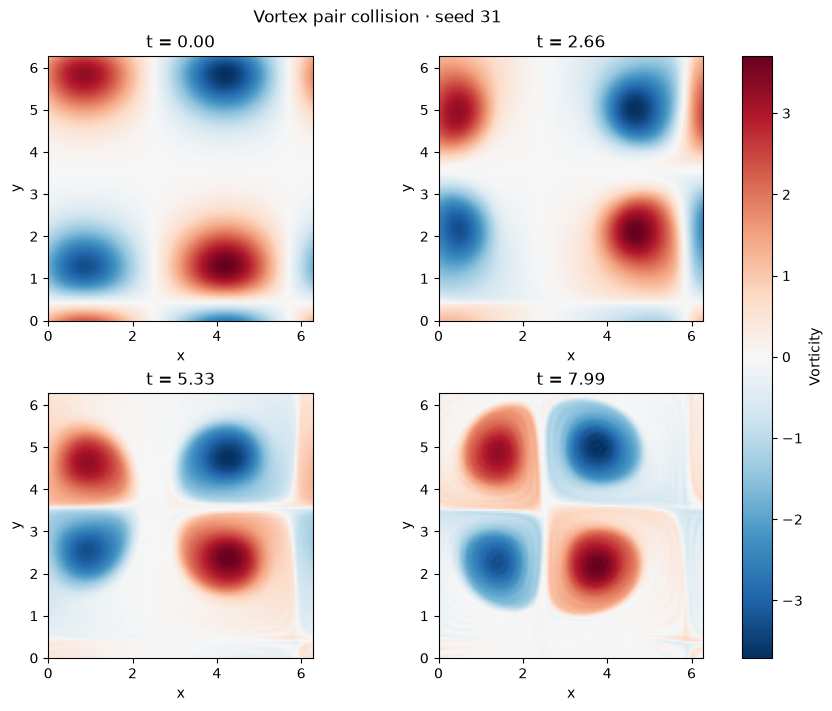

In [44]:
# Reverse the signs in the right pair so the two pairs travel toward each other.
def periodic_blob(center_x, center_y, width):
    dx = (x_grid - center_x + domain_length / 2) % domain_length - domain_length / 2
    dy = (y_grid - center_y + domain_length / 2) % domain_length - domain_length / 2
    return jnp.exp(-(dx**2 + dy**2) / (16 * width**2))


def collision_vorticity(
    *, center_x, center_y, pair_distance, lateral_offset,
    left_spacing, right_spacing, left_strength, right_strength, vortex_width,
):
    """Build two opposing vortex pairs with equal and opposite signs within each pair."""
    left_x = center_x - pair_distance / 2
    right_x = center_x + pair_distance / 2
    left_y = center_y - lateral_offset / 2
    right_y = center_y + lateral_offset / 2
    left_pair = (
        periodic_blob(left_x, left_y + left_spacing / 2, vortex_width)
        - periodic_blob(left_x, left_y - left_spacing / 2, vortex_width)
    )
    right_pair = (
        periodic_blob(right_x, right_y - right_spacing / 2, vortex_width)
        - periodic_blob(right_x, right_y + right_spacing / 2, vortex_width)
    )
    return left_strength * left_pair + right_strength * right_pair


def sample_collision_parameters(seed):
    """Draw a reproducible variation of the head-on collision."""
    rng = np.random.default_rng(seed)
    return dict(
        center_x=rng.uniform(0, float(domain_length)),
        center_y=rng.uniform(0, float(domain_length)),
        pair_distance=rng.uniform(2.7, 3.05),
        lateral_offset=rng.uniform(-0.2, 0.2),
        left_spacing=rng.uniform(0.65, 0.85),
        right_spacing=rng.uniform(0.65, 0.85),
        left_strength=rng.uniform(7.0, 9.0),
        right_strength=rng.uniform(7.0, 9.0),
        vortex_width=0.3,
    )


# Change the seed to try another setup, or edit the sampled parameters directly.
collision_seed = 31
collision_parameters = sample_collision_parameters(collision_seed)
collision_initial = collision_vorticity(**collision_parameters)
collision_viscosity = 0.0
collision_speed_bound = 7
collision_courant_factor = 0.5
collision_duration = 8.0
collision_snapshot_count = 3
collision_spectra, collision_time_step, _ = simulate_vorticity(
    grid, jnp.fft.rfftn(collision_initial),
    viscosity=collision_viscosity,
    max_flow_speed=collision_speed_bound,
    courant_factor=collision_courant_factor,
    target_time=collision_duration, snapshot_count=collision_snapshot_count,
)
collision_snapshots = jnp.fft.irfftn(
    collision_spectra, s=(grid_size, grid_size), axes=(-2, -1)
)
collision_times = np.arange(collision_snapshot_count + 1) * int(
    (collision_duration // collision_time_step) // collision_snapshot_count
) * collision_time_step

fig, axes = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")
fig.suptitle(f"Vortex pair collision · seed {collision_seed}")
peak = float(jnp.max(jnp.abs(collision_initial)))
for ax, time, field in zip(axes.flat, collision_times, [collision_initial, *collision_snapshots]):
    image = ax.imshow(
        np.asarray(field).T, origin="lower", cmap="RdBu_r",
        extent=(0, float(domain_length), 0, float(domain_length)),
        vmin=-peak, vmax=peak,
    )
    ax.set(title=f"t = {time:.2f}", xlabel="x", ylabel="y")
fig.colorbar(image, ax=axes, label="Vorticity")
plt.show()
